<a href="https://colab.research.google.com/github/f26-sjsu-cmpe188/CA6/blob/main/SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Student nam: Thien Doan

SJSU ID: 018793021

github: https://github.com/f26-sjsu-cmpe188/CA6/blob/7de182d8bb039c839d54f67e9da71cfa171bb7de/SVM.ipynb

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn import svm
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/xor_wedge_20.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x1      20 non-null     float64
 1   x2      20 non-null     float64
 2   wedge   20 non-null     object 
 3   y       20 non-null     int64  
dtypes: float64(2), int64(1), object(1)
memory usage: 772.0+ bytes


Prep the dataset with the x0 column

<Axes: xlabel='x1', ylabel='x2'>

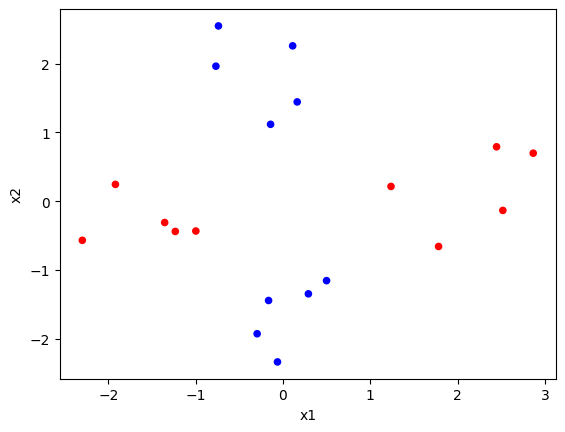

In [ ]:
col = df['y'].map({-1:'b', 1:'r'})
df.plot.scatter(x='x1', y='x2', c=col)

Prompt 1: Try variants of the kernel, C, and polynomial degree or gamma if applicable. Looking at the resuling graphs, which kernel seems to fit best for this dataset?

- The degree = 2 and C = 1, make the kernel seems to fit best the dataset.

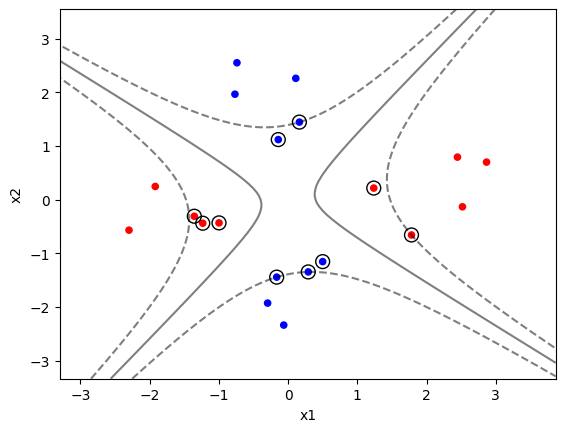

In [ ]:
x = df[['x1', 'x2']]
y = df['y']
#clf = svm.SVC(kernel="linear", C=1)
clf = svm.SVC(kernel="poly", degree=2, C=1)
#clf = svm.SVC(kernel="rbf", gamma=0.1, C=1)
clf.fit(x,y)

from sklearn.inspection import DecisionBoundaryDisplay

df.plot.scatter(x='x1', y='x2', c=col)
ax = plt.gca()
DecisionBoundaryDisplay.from_estimator(
    clf,
    x,
    plot_method="contour",
    colors="k",
    levels=[-1, 0, 1],
    alpha=0.5,
    linestyles=["--", "-", "--"],
    ax=ax,
)

#plot support vectors
ax.scatter(
    clf.support_vectors_[:, 0],
    clf.support_vectors_[:, 1],
    s=100,
    linewidth=1,
    facecolors="none",
    edgecolors="k",
)
plt.show()

In [ ]:
len(clf.support_vectors_)

17

In [ ]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.01, 0.1, 1]
}

# Initialize GridSearchCV
grid_search = GridSearchCV(svm.SVC(kernel='rbf'), param_grid, cv=5, scoring='accuracy')
grid_search.fit(x, y)

print(f"Best Parameters from CV: {grid_search.best_params_}")
print(f"Best CV Accuracy: {grid_search.best_score_:.4f}")

Best Parameters from CV: {'C': 0.1, 'gamma': 'scale'}
Best CV Accuracy: 1.0000


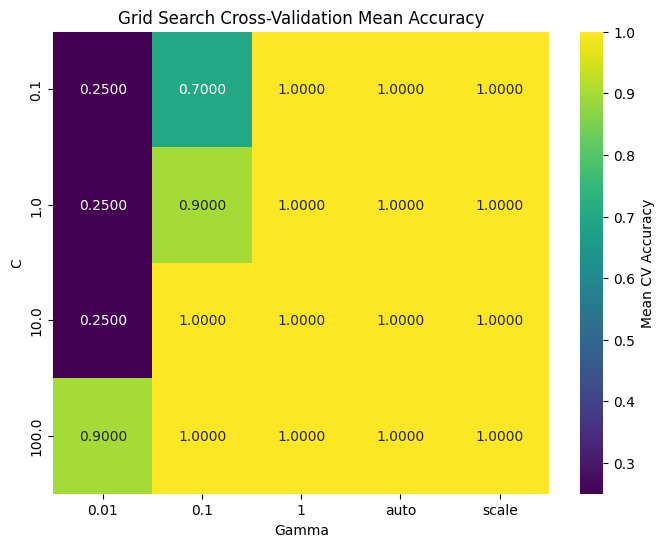

In [ ]:
# Extract grid search results
results = pd.DataFrame(grid_search.cv_results_)

# Reshape results into a pivot table for the heatmap
# Since gamma can be numeric or strings like 'scale'/'auto', convert them to string labels
results['param_gamma'] = results['param_gamma'].astype(str)
pivot_table = results.pivot(index='param_C', columns='param_gamma', values='mean_test_score')

# Plot the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(pivot_table, annot=True, fmt=".4f", cmap="viridis", cbar_kws={'label': 'Mean CV Accuracy'})
plt.title("Grid Search Cross-Validation Mean Accuracy")
plt.xlabel("Gamma")
plt.ylabel("C")
plt.show()

Prompt 2: Below is the code to find the test error on the test dataset. Do the results meet expectations? Please add cell blocks to also display the confusion matrix.

Test Set Accuracy: 0.9250


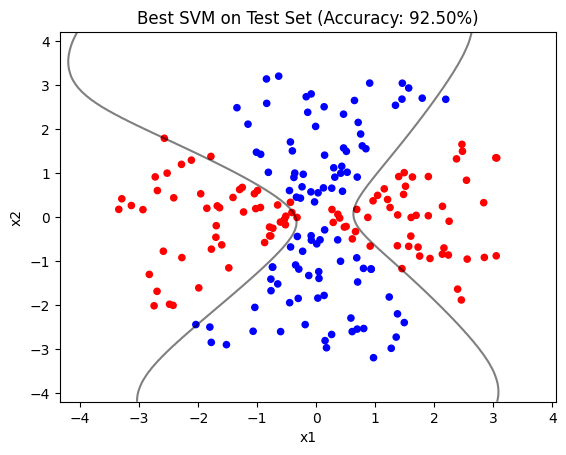

In [ ]:
import os

test_path = '/content/drive/MyDrive/xor_wedge_test.csv'
if os.path.exists(test_path):
    # Load the test dataset
    df_test = pd.read_csv(test_path)
    x_test = df_test[['x1', 'x2']]
    y_test = df_test['y']

    # Best model
    best_clf = grid_search.best_estimator_

    # Predict and evaluate
    test_acc = best_clf.score(x_test, y_test)
    print(f"Test Set Accuracy: {test_acc:.4f}")

    # Plot Decision Boundary with Test Data
    test_col = y_test.map({-1:'b', 1:'r'})
    df_test.plot.scatter(x='x1', y='x2', c=test_col)
    ax = plt.gca()

    DecisionBoundaryDisplay.from_estimator(
        best_clf,
        x_test,
        plot_method="contour",
        colors="k",
        levels=[-1, 0, 1],
        alpha=0.5,
        linestyles=["--", "-", "--"],
        ax=ax,
    )
    plt.title(f"Best SVM on Test Set (Accuracy: {test_acc:.2%})")
    plt.show()
else:
    print(f"Test file {test_path} not found.")

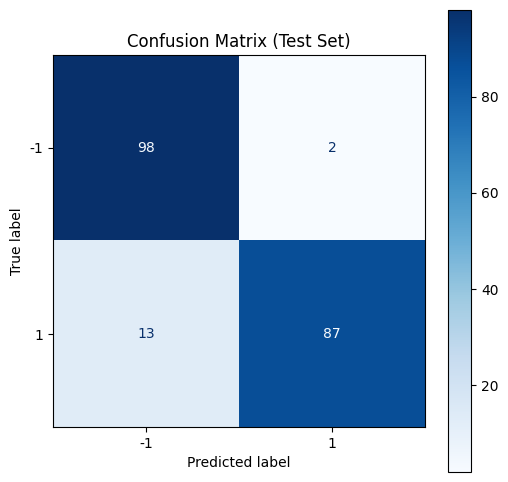

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Compute predictions on the test set
y_pred = best_clf.predict(x_test)

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=best_clf.classes_)

# Plot the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_clf.classes_)
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap='Blues', ax=ax)
plt.title("Confusion Matrix (Test Set)")
plt.show()

The test set accuracy hit 92.5%, so the result meet the requiremnts, as it work well on unseen data.